In [1]:
# ====================================================
# Libraries
# ====================================================

import numpy as np
import matplotlib.pyplot as plt
from getdist import MCSamples, plots

In [2]:
# ====================================================
# File paths
# ====================================================

fname_noFRB = "/home/brunowesley/projetos/MCMC-cosmo/Codes/GR-based/wCDM/CC_SNe_BAO/flat_samples_wCDM_cc_sne_bao.npy"
fname_FRB   = "/home/brunowesley/projetos/MCMC-cosmo/Codes/GR-based/wCDM/CC_SNe_BAO_FRB/flat_samples_wCDM_cc_sne_bao_frb.npy"


# ====================================================
# Load samples (FULL chains)
# ====================================================

samples_noFRB_full = np.load(fname_noFRB)
samples_FRB_full   = np.load(fname_FRB)

print("No FRB (full):", samples_noFRB_full.shape)
print("With FRB (full):", samples_FRB_full.shape)

No FRB (full): (1192280, 5)
With FRB (full): (1665944, 7)


In [3]:
# ====================================================
# Function: marginalized statistics (PRINT + SAVE)
# ====================================================

def print_stats(flat_samples, param_names_indices, fmt_map, title, file=None):

    lines = []
    lines.append("\n" + "="*60)
    lines.append(f"{title:^60}")
    lines.append("="*60)

    for name, idx in param_names_indices:
        samples = flat_samples[:, idx]

        median  = np.percentile(samples, 50)
        lower68 = np.percentile(samples, 16)
        upper68 = np.percentile(samples, 84)
        lower95 = np.percentile(samples, 2.5)
        upper95 = np.percentile(samples, 97.5)

        ep68 = upper68 - median
        em68 = median  - lower68
        ep95 = upper95 - median
        em95 = median  - lower95

        fmt = fmt_map.get(name, ".3f")

        lines.append(f"\n  {name}:")
        lines.append(f"    {median:{fmt}} +{ep68:{fmt}} -{em68:{fmt}}  (68% CL)")
        lines.append(f"    {median:{fmt}} +{ep95:{fmt}} -{em95:{fmt}}  (95% CL)")

    lines.append("\n" + "="*60)

    for line in lines:
        print(line)

    if file is not None:
        for line in lines:
            file.write(line + "\n")


# ====================================================
# Save ALL output to file
# ====================================================

output_file = "stats_wCDM_full.txt"

with open(output_file, "w", encoding="utf-8") as f:

    # ====================================================
    # Statistics: WITHOUT FRB
    # ====================================================

    # 🔥 ORDEM CORRETA
    param_noFRB = [
        ("H0", 0),
        ("Om0", 1),
        ("Ob", 2),
        ("MB", 3),
        ("w", 4)
    ]

    fmt_noFRB = {
        "H0": ".2f",
        "Om0": ".3f",
        "Ob": ".4f",
        "MB": ".3f",
        "w": ".3f"
    }

    print_stats(
        samples_noFRB_full,
        param_noFRB,
        fmt_noFRB,
        "wCDM | CC + SNe + BAO",
        file=f
    )

    # ====================================================
    # Statistics: WITH FRB
    # ====================================================

    param_FRB = [
        ("H0", 0),
        ("Om0", 1),
        ("Ob", 2),
        ("MB", 3),
        ("w", 4),
        ("sigma_host", 5),
        ("exp_mu", 6)
    ]

    fmt_FRB = {
        "H0": ".2f",
        "Om0": ".3f",
        "Ob": ".4f",
        "MB": ".3f",
        "w": ".3f",
        "sigma_host": ".3f",
        "exp_mu": ".1f"
    }

    print_stats(
        samples_FRB_full,
        param_FRB,
        fmt_FRB,
        "wCDM | CC + SNe + BAO + FRB",
        file=f
    )

print(f"\n✅ Full output saved to: {output_file}")


                   wCDM | CC + SNe + BAO                    

  H0:
    67.51 +1.56 -1.55  (68% CL)
    67.51 +3.08 -3.03  (95% CL)

  Om0:
    0.298 +0.009 -0.009  (68% CL)
    0.298 +0.018 -0.017  (95% CL)

  Ob:
    0.0548 +0.0043 -0.0039  (68% CL)
    0.0548 +0.0090 -0.0074  (95% CL)

  MB:
    -19.413 +0.048 -0.049  (68% CL)
    -19.413 +0.094 -0.097  (95% CL)

  w:
    -0.880 +0.039 -0.040  (68% CL)
    -0.880 +0.077 -0.079  (95% CL)


                wCDM | CC + SNe + BAO + FRB                 

  H0:
    67.75 +1.30 -1.30  (68% CL)
    67.75 +2.54 -2.57  (95% CL)

  Om0:
    0.297 +0.008 -0.008  (68% CL)
    0.297 +0.016 -0.016  (95% CL)

  Ob:
    0.0556 +0.0026 -0.0025  (68% CL)
    0.0556 +0.0051 -0.0048  (95% CL)

  MB:
    -19.405 +0.038 -0.039  (68% CL)
    -19.405 +0.074 -0.077  (95% CL)

  w:
    -0.877 +0.036 -0.036  (68% CL)
    -0.877 +0.069 -0.072  (95% CL)

  sigma_host:
    0.860 +0.134 -0.111  (68% CL)
    0.860 +0.287 -0.200  (95% CL)

  exp_mu:
    95.0 +16.3 

Removed no burn in
Removed no burn in


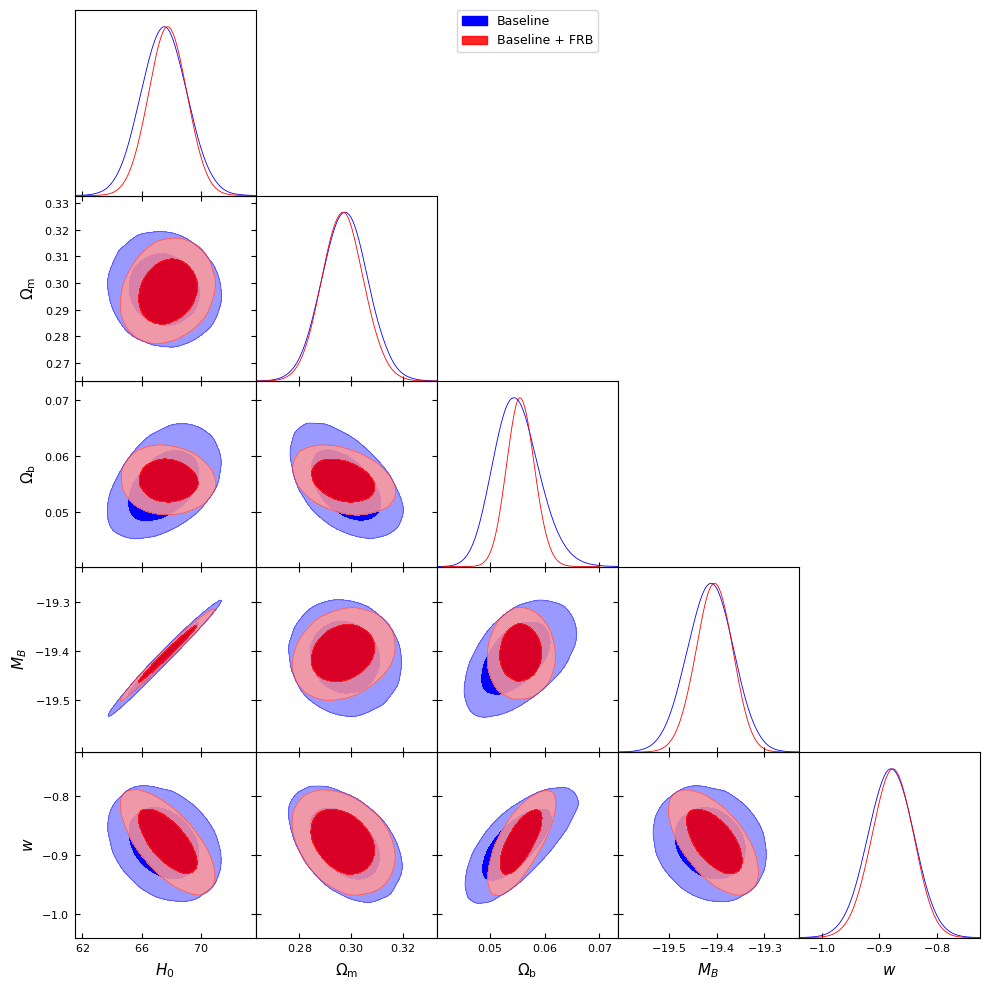

In [4]:
# ====================================================
# Parameters for corner plot
# ====================================================

idx = [0, 1, 2, 3, 4]

samples_noFRB = samples_noFRB_full[:, idx]
samples_FRB   = samples_FRB_full[:, idx]

param_names  = ["H0", "Om0", "Ob", "MB", "w"]
param_labels = [r"H_0", r"\Omega_{\rm m}", r"\Omega_{\rm b}", r"M_B", r"w"]

# ====================================================
# GetDist
# ====================================================

gd_noFRB = MCSamples(samples=samples_noFRB,
                     names=param_names,
                     labels=param_labels)

gd_FRB   = MCSamples(samples=samples_FRB,
                     names=param_names,
                     labels=param_labels)

for gd in [gd_noFRB, gd_FRB]:
    gd.updateSettings({
        "smooth_scale_1D": 0.25,
        "smooth_scale_2D": 0.25,
        "fine_bins": 1024,
        "fine_bins_2D": 1024,
    })

# ====================================================
# Corner plot
# ====================================================

g = plots.get_subplot_plotter()

g.triangle_plot(
    [gd_noFRB, gd_FRB],
    filled=True,
    legend_labels=[r"Baseline", r"Baseline + FRB"],
    contour_colors=["blue", "red"],
    title_limit=0
)

plt.savefig("Corner_wCDM_comparison.png", dpi=300, bbox_inches="tight")
plt.savefig("Corner_wCDM_comparison.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [5]:
# ========================================================
# Derived Parameter: Sound Horizon rd
# ========================================================

Neff = 3.046 

def compute_rd_chain(flat_samples):
    H0  = flat_samples[:, 0]
    Om0 = flat_samples[:, 1]
    Ob  = flat_samples[:, 2]

    h2   = (H0 / 100.0)**2
    Obh2 = Ob * h2
    Omh2 = Om0 * h2

    rd = 147.05 * ((Obh2 / 0.02236)**-0.13) \
                 * ((Omh2 / 0.1432)**-0.23) \
                 * ((Neff  / 3.04)**-0.1)

    return rd


def print_rd_stats(rd_chain, title):

    median  = np.percentile(rd_chain, 50)
    lower68 = np.percentile(rd_chain, 16)
    upper68 = np.percentile(rd_chain, 84)
    lower95 = np.percentile(rd_chain, 2.5)
    upper95 = np.percentile(rd_chain, 97.5)

    ep68 = upper68 - median
    em68 = median  - lower68
    ep95 = upper95 - median
    em95 = median  - lower95

    print("\n" + "="*60)
    print(f"{title:^60}")
    print("="*60)

    print(f"\n  r_d:")
    print(f"    {median:.3f} +{ep68:.3f} -{em68:.3f}  (68% CL)")
    print(f"    {median:.3f} +{ep95:.3f} -{em95:.3f}  (95% CL)")

    print("\n" + "="*60)


# ========================================================
# Compute rd for both datasets
# ========================================================

rd_noFRB = compute_rd_chain(samples_noFRB_full)
rd_FRB   = compute_rd_chain(samples_FRB_full)


# ========================================================
# Print results
# ========================================================

print_rd_stats(rd_noFRB, "Sound Horizon r_d | CC + SNe + BAO")
print_rd_stats(rd_FRB,   "Sound Horizon r_d | CC + SNe + BAO + FRB")


             Sound Horizon r_d | CC + SNe + BAO             

  r_d:
    146.754 +3.257 -3.113  (68% CL)
    146.754 +6.482 -6.020  (95% CL)


          Sound Horizon r_d | CC + SNe + BAO + FRB          

  r_d:
    146.186 +2.426 -2.306  (68% CL)
    146.186 +4.855 -4.458  (95% CL)

